In [1]:
import nbiatoolkit
print(nbiatoolkit.__version__)



0.29.2


In [2]:

import sys
import os
import numpy as np
import pandas as pd
sys.path.append(os.path.curdir + '/..')
from Dataset.custom_dataset import get_data_loaders
from pycox.evaluation import EvalSurv
from statsmodels.stats.proportion import proportion_confint
import Dataset
print(Dataset.__name__)



IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


Dataset


In [3]:
# def sample_from_dist(params, distributions):
#     """
#     Generates samples from specified distribution parameters.
    
#     Args:
#         params (torch.Tensor): Tensor of distribution parameters, expected shape [batch_size, 2]
#                                where params[:, 0] = alpha and params[:, 1] = lambda for Weibull.
#         distributions (list): List specifying distribution types, e.g., ['weibull'].

#     Returns:
#         numpy.ndarray: Array of generated samples from specified distributions.
#     """
#     samples = []
#     for dist in distributions:
#         if dist == 'weibull':
#             alpha, lam = params[:, 0], params[:, 1]  # Extract Weibull parameters
#             # Sample from Weibull distribution
#             weibull_samples = lam * (-torch.log(torch.rand_like(alpha))) ** (1 / alpha)
#             samples.append(weibull_samples.cpu().numpy())  # Convert samples to numpy
#         else:
#             raise NotImplementedError(f"Unknown distribution type: {dist}")
    
#     # Concatenate all samples along the batch dimension
#     return np.concatenate(samples, axis=0)

In [4]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class Encoder3D(nn.Module):
    def __init__(self, in_channels, base_channels):
        super(Encoder3D, self).__init__()
        
        self.encoder = nn.Sequential(
            nn.Conv3d(in_channels, base_channels, kernel_size=3, padding=1),
            nn.BatchNorm3d(base_channels),
            nn.ReLU(inplace=True),
            nn.Conv3d(base_channels, base_channels, kernel_size=3, padding=1),
            nn.BatchNorm3d(base_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=2)  # Downsample by 2
        )
    
    def forward(self, x):
        return self.encoder(x)
class Decoder3D(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(Decoder3D, self).__init__()
        
        self.decoder = nn.Sequential(
            nn.ConvTranspose3d(in_channels, out_channels, kernel_size=2, stride=2),  # Upsample by 2
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),
        )
    
    def forward(self, x):
        return self.decoder(x)

class TimeDecoder(nn.Module):
    def __init__(self, input_dim):
        super(TimeDecoder, self).__init__()
        # Intermediate dimension
        intermediate_dim = input_dim * 2  # You can adjust this multiplier as necessary
        
        # Define a series of Linear layers and ReLUs
        self.layers = nn.Sequential(
            nn.Linear(input_dim, intermediate_dim),
            nn.ReLU(),
            nn.Linear(intermediate_dim  , intermediate_dim * 2 ),
            nn.ReLU(),
            nn.Linear(intermediate_dim * 2, intermediate_dim),
            nn.ReLU(),
            nn.Linear(intermediate_dim, intermediate_dim // 2),
            nn.ReLU(),
            nn.Linear(intermediate_dim // 2, 2)  # Outputs the shape and scale parameters
        )
        self.softplus = nn.Softplus() 

    def forward(self, z):
        return self.softplus(self.layers(z))
        #return self.layers(z)

# class TimeDecoder2(nn.Module):
#     def __init__(self, input_dim):
#         super(TimeDecoder2, self).__init__()
#         # Intermediate dimension
#         intermediate_dim = input_dim * 2  # You can adjust this multiplier as necessary
        
#         # Define a series of Linear layers and ReLUs
#         self.layers1 = nn.Sequential(
#             nn.Linear(input_dim, intermediate_dim),
#             nn.ReLU(),
#             nn.Linear(intermediate_dim, intermediate_dim // 2),
#             nn.ReLU(),
#             nn.Linear(intermediate_dim // 2, 1)  # Outputs the shape and scale parameters
#         )

#         self.layers2 = nn.Sequential(
#             nn.Linear(input_dim, intermediate_dim),
#             nn.ReLU(),
#             nn.Linear(intermediate_dim, intermediate_dim // 2),
#             nn.ReLU(),
#             nn.Linear(intermediate_dim // 2, 1)  # Outputs the shape and scale parameters
#         )

#         self.softplus = nn.Softplus() 

#     def forward(self, z):
#         alpha = self.softplus(self.layers1(z[:, 0]))
#         lam = self.softplus(self.layers2(z[:, 0]))
#         return torch.cat([alpha, lam]) 



In [5]:

class LatentSpaceGaussian(nn.Module):
    def __init__(self, latent_dim):
        super(LatentSpaceGaussian, self).__init__()
        self.latent_dim = latent_dim
        self.latent_params = 2 * latent_dim  # Two parameters are needed for each Gaussian distribution


    def get_latent_params(self, x):
        x = x.view(-1, 2, self.latent_dim)
        mu = x[:, 0, :]
        log_var = x[:, 1, :]
        return mu, log_var


    def sample_latent(self, latent_params):
        mu, log_var = latent_params
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)  # `randn_like` as we need the same size
        z = mu + (eps * std)  # sampling as if coming from the input space
        return z


    def kl_loss(self, latent_params):
        mu, log_var = latent_params
        kl = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())  # Kullback-Leibler divergence
        return kl / mu.shape[0]


In [6]:

class LogLikelihoodLossWithCensoring(nn.Module):
    def __init__(self, dist_type):
        """
        Initialize the log-likelihood loss with censoring class.
        
        Args:
            dist_type (str): Distribution type to use for survival prediction (currently only supports 'weibull').
        """
        super(LogLikelihoodLossWithCensoring, self).__init__()
        self.dist_type = dist_type

    # def forward(self, inputs, survival_times, risk_status):
    #     survival_times = torch.clamp(torch.squeeze(survival_times), min=1e-8)
    #     risk_status = torch.squeeze(risk_status)

    #     # Extract and clamp Weibull parameters
    #     alpha = torch.clamp(inputs[:, 0], min=1e-8, max=5)
    #     lam = torch.clamp(inputs[:, 1], min=1e-8)

    #     # Calculate stable survival log-probabilities
    #     safe_ratio = torch.clamp(survival_times / lam, min=1e-8, max=100)
    #     survival_term = -torch.pow(safe_ratio, alpha)
    #     hazard_term = torch.log(alpha / lam) + (alpha - 1) * torch.log(safe_ratio)

    #     # Debugging: Check for NaNs or Infs in intermediate calculations
    #     if torch.any(torch.isnan(survival_term)) or torch.any(torch.isinf(survival_term)):
    #         print("Warning: NaN or Inf detected in survival_term")
    #         print("alpha:", alpha)
    #         print("lam:", lam)
    #         print("survival_times:", survival_times)
    #         print("safe_ratio (survival_times / lam):", safe_ratio)

    #     if torch.any(torch.isnan(hazard_term)) or torch.any(torch.isinf(hazard_term)):
    #         print("Warning: NaN or Inf detected in hazard_term")
    #         print("alpha:", alpha)
    #         print("lam:", lam)
    #         print("survival_times:", survival_times)
    #         print("safe_ratio (survival_times / lam):", safe_ratio)

    #     # Apply censoring
    #     log_likelihood_loss = -torch.sum(hazard_term[risk_status > 0.5]) - torch.sum(survival_term)

    #     # Mean loss across batch
    #     loss = log_likelihood_loss / inputs.size(0)

    #     # Ensure finite loss
    #     if not torch.isfinite(loss):
    #         raise ValueError("Non-finite loss encountered, check inputs for stability issues.")

    #     return loss


    def forward(self, inputs, survival_times, risk_status):
        """
        Compute the log-likelihood loss with censoring.
        
        Args:
            inputs (Tensor): Weibull parameters (alpha and lambda) predicted by the model, shape [batch_size, 2].
            survival_times (Tensor): Actual survival times for each sample, shape [batch_size].
            risk_status (Tensor): Binary censoring indicators (1 if event occurred, 0 if censored), shape [batch_size].

        Returns:
            loss (Tensor): Mean log-likelihood loss with censoring.
        """
        survival_times = torch.squeeze(survival_times)
        risk_status = torch.squeeze(risk_status)

        # Extract Weibull parameters from inputs
        alpha = inputs[:, 0]
        lam = inputs[:, 1]

        # Calculate the survival log-probabilities
        survival_term = -torch.pow(survival_times / lam, alpha)
        #print(survival_term)
        # Calculate the hazard function where risk_status is 1
        hazard_term = torch.log(alpha / lam) + (alpha - 1) * torch.log(survival_times / lam)
        #print(hazard_term)
        # Apply the censoring: use hazard term only where risk status is 1 (event occurred)
        # Debugging: Check for NaNs or Infs in intermediate calculations
        if torch.any(torch.isnan(survival_term)) or torch.any(torch.isinf(survival_term)):
            print("Warning: NaN or Inf detected in survival_term")
            print("alpha:", alpha)
            print("lam:", lam)
            print("survival_times:", survival_times)
            print("survival_term:", survival_term)

        if torch.any(torch.isnan(hazard_term)) or torch.any(torch.isinf(hazard_term)):
            print("Warning: NaN or Inf detected in hazard_term")
            print("alpha:", alpha)
            print("lam:", lam)
            print("survival_times:", survival_times)
            print("hazard_term:", hazard_term)

        # Apply censoring
        log_likelihood_loss = -torch.sum(hazard_term[risk_status > 0.5]) - torch.sum(survival_term)

        # Mean loss across batch
        loss = log_likelihood_loss / inputs.size(0)

        # Ensure finite loss
        if not torch.isfinite(loss):
            raise ValueError("Non-finite loss encountered, check inputs for stability issues.")

        return loss


In [7]:
# # Create dummy variables
# batch_size = 5  # Example batch size
# inputs = torch.tensor([[2.0, 1.0],  # alpha, lambda for sample 1
#                        [1.5, 0.5],  # alpha, lambda for sample 2
#                        [3.0, 2.0],  # alpha, lambda for sample 3
#                        [1.0, 1.0],  # alpha, lambda for sample 4
#                        [2.5, 1.5]], # alpha, lambda for sample 5
#                       dtype=torch.float32)  # Weibull parameters (alpha, lambda)

# survival_times = torch.tensor([10.0, 5.0, 15.0, 20.0, 25.0], dtype=torch.float32)  # Survival times
# risk_status = torch.tensor([1, 1, 0, 1, 0], dtype=torch.float32)  # Risk status (1 if event occurred, 0 if censored)

# # Create an instance of the loss class
# loss_fn = LogLikelihoodLossWithCensoring(dist_type='weibull')

# # Compute the loss
# loss = loss_fn(inputs, survival_times, risk_status)

# # Print the loss
# print(f"Log-likelihood loss: {loss.item()}")

In [8]:
import torch
import torch.nn as nn

class UNet3D(nn.Module):
    def __init__(self, in_channels, out_channels, base_channels, latent_dim=None):
        super(UNet3D, self).__init__()
        
        self.latent_dim = latent_dim
        self.rec_loss = nn.MSELoss() 
        self.time_loss = LogLikelihoodLossWithCensoring(dist_type='weibull')
        
        # Encoder layers
        self.enc1 = Encoder3D(in_channels, base_channels)
        self.enc2 = Encoder3D(base_channels, base_channels * 2)
        self.enc3 = Encoder3D(base_channels * 2, base_channels * 4)
        self.enc4 = Encoder3D(base_channels * 4, base_channels * 8)
        
        if latent_dim is not None:
            # Separate layers for mu and logvar
            self.mu = nn.Linear(base_channels * 8 * 8 * 8 * 4, latent_dim)
            self.logvar = nn.Linear(base_channels * 8 * 8 * 8 * 4, latent_dim)
            self.fc_decode = nn.Linear(latent_dim, base_channels * 8 * 8 * 8 * 4)  # Reshape latent back to decoder input size
        
        # Decoder layers
        self.dec4 = Decoder3D(base_channels * 8, base_channels * 4)
        self.dec3 = Decoder3D(base_channels * 4, base_channels * 2)
        self.dec2 = Decoder3D(base_channels * 2, base_channels)
        self.dec1 = Decoder3D(base_channels, out_channels)

        if latent_dim is not None:
            self.time_decoder = TimeDecoder(latent_dim)
    
    def forward(self, x):
        batch_size, _, H, W, D = x.shape 
        out_data = {}  # Dictionary to store outputs
        
        # Encoding path
        enc1 = self.enc1(x)
        enc2 = self.enc2(enc1)
        enc3 = self.enc3(enc2)
        enc4 = self.enc4(enc3)
        
        if self.latent_dim is not None:
            # Flatten for mu and logvar calculations
            enc4_flat = enc4.view(enc4.size(0), -1)
            
            # Calculate `mu` and `log_var` using separate layers
            mu = self.mu(enc4_flat)
            log_var = self.logvar(enc4_flat)
            
            # Sample from latent space using reparameterization trick
            std = torch.exp(0.5 * log_var)
            eps = torch.randn_like(std)
            z = mu + eps * std
            #print("z",z)
            # Decode the latent sample
            enc4_decoded = self.fc_decode(z).view(batch_size, -1, 8, 8, 4)
            print(enc4_decoded.shape)
            
            # Predict Weibull parameters
            weibull_params = self.time_decoder(z)
            print("weibull_params",weibull_params)
            # Calculate KL divergence
            kl_divergence = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
            
            # Add outputs to the dictionary
            out_data['latent_sample'] = z
            out_data['mu'] = mu
            out_data['log_var'] = log_var
            out_data['time_params'] = weibull_params
            out_data['kl_divergence'] = kl_divergence
            enc4 = enc4_decoded  # Use the decoded latent sample for further decoding
        
        # Decoding path
        dec4 = self.dec4(enc4)
        dec3 = self.dec3(dec4 + enc3)
        dec2 = self.dec2(dec3 + enc2)
        dec1 = self.dec1(dec2 + enc1)
        
        # Reconstruction output
        out_data['reconstruction'] = dec1
        
        return out_data


    @staticmethod
    def sample_from_dist(params, distributions):
        """
        Generates samples from specified distribution parameters.
        
        Args:
            params (torch.Tensor): Tensor of distribution parameters, expected shape [batch_size, 2]
                                where params[:, 0] = alpha and params[:, 1] = lambda for Weibull.
            distributions (list): List specifying distribution types, e.g., ['weibull'].

        Returns:
            numpy.ndarray: Array of generated samples from specified distributions.
        """
        samples = []
        for dist in distributions:
            if dist == 'weibull':
                alpha, lam = params[:, 0], params[:, 1]  # Extract Weibull parameters
                alpha = torch.clamp(alpha, min=0.2)  # Prevent alpha from being zero or negative
                lam = torch.clamp(lam, min=0.2)
                # Sample from Weibull distribution
                weibull_samples = lam * (-torch.log(torch.rand_like(alpha))) ** (1 / alpha)
                if (weibull_samples <= 0).any():
                    print("Non-positive samples detected:", weibull_samples[weibull_samples <= 0])

                samples.append(weibull_samples.detach().cpu().numpy())  # Convert samples to numpy
            else:
                raise NotImplementedError(f"Unknown distribution type: {dist}")
        
        # Concatenate all samples along the batch dimension
        return np.concatenate(samples, axis=0)

    def predict_time(self, x, device=torch.device('cuda:3')):
        """
        Predicts Weibull time distribution parameters and samples for survival analysis
        using only image data.
        
        Args:
            x (torch.Tensor): Input image tensor of shape [batch_size, channels, H, W, D].
            device (torch.device, optional): Device to run the computations on (e.g., 'cpu' or 'cuda').

        Returns:
            dict: Dictionary with keys 'z', 'time_params', and 'time_samples':
                - 'z': Latent representation from image input.
                - 'time_params': Predicted Weibull distribution parameters.
                - 'time_samples': Sampled time prediction based on Weibull distribution.
        """
        # Ensure input is on the correct device
        x = x.to(device)
        
        # Forward pass through the network to get latent representation and time parameters
        out_data = self.forward(x)
        
        # Get latent variable z from the output data dictionary
        z = out_data['latent_sample']  # Latent representation
        time_params = out_data['time_params']  # Weibull distribution parameters
        
        # Generate a survival time sample from the Weibull distribution
        time_samples = self.sample_from_dist(time_params, distributions=['weibull'])
        
        return {
            'z': z.detach().cpu().numpy(),  # Detach and convert to NumPy array
            'time_params': time_params.detach().cpu().numpy(),
            'time_samples': time_samples
        }


    def predict_just_time(self, x):
        """Predicts only the time samples based on the input covariates."""
        # Call the predict_time method to get time samples
        return self.predict_time(x)['time_samples']


    @staticmethod
    def bern_conf_interval(n, mean, ibs=False):
        # Confidence interval
        ci_bot, ci_top = proportion_confint(count=mean * n, nobs=n, alpha=0.1, method='beta')
        if mean < 0.5 and not ibs:
            ci_bot_2 = 1 - ci_top
            ci_top = 1 - ci_bot
            ci_bot = ci_bot_2
            mean = 1 - mean

        return np.round(ci_bot, 4), mean, np.round(ci_top, 4)

    @staticmethod
    def obtain_c_index(surv_f, time, censor):
        # Evaluate using PyCox c-index
        ev = EvalSurv(surv_f, time.flatten(), censor.flatten(), censor_surv='km')
        ci = ev.concordance_td()

        # Obtain also ibs
        time_grid = np.linspace(time.min(), time.max(), 100)
        ibs = ev.integrated_brier_score(time_grid)
        return ci, ibs
        
    def calculate_risk(self, time_train, x_val, censor_val):
        """Calculate risk CDF at specified time points, compute C-index and IBS with confidence intervals."""
        # time_train = time_train.detach().cpu().numpy()
        # times = np.unique(time_train)
        # Ensure time_train is a list of numerical values

        # Print the type of time_train
        print("Type of time_train:", type(time_train))
        
        # if isinstance(time_train, list):
        #     # Convert list to a numpy array for easier manipulation
        #     time_train_array = np.array(time_train, dtype=float)
        #     # Print the shape of the converted array
        #     print("Shape of time_train:", time_train_array.shape)
        #     times = np.unique(time_train_array)  # Use the array with np.unique
        # else:
        #     # If time_train is not a list, assume it's a NumPy array and print its shape
        #     print("Shape of time_train:", time_train.shape)
        #     times = np.unique(time_train) 


        time_train = time_train.detach().cpu().numpy()
        times = np.unique(time_train)
        out_data = self.predict_time(x_val)
        pred_risk = np.zeros((out_data['time_params'].shape[0], len(times)))

        for sample in range(pred_risk.shape[0]):
            # Directly assume the Weibull parameters are used
            alpha = out_data['time_params'][sample, 0]
            lam = out_data['time_params'][sample, 1]
            pred_risk[sample, :] = 1 - np.exp(-np.power(times / lam, alpha))

        # Calculate C-index and IBS along with confidence intervals
        ci, ibs = self.obtain_c_index(pd.DataFrame(1 - pred_risk.T, index=times), np.asarray(time_train), np.asarray(censor_val))
        ci_conf_intervals = self.bern_conf_interval(len(np.asarray(time_train)), ci)
        ibs_conf_intervals = self.bern_conf_interval(len(np.asarray(time_train)), ibs, ibs=True)

        return ci_conf_intervals, ibs_conf_intervals

    def fit_epoch(self, train_loader, test_loader, optimizer, device=None):
        # Automatically determine device if not provided
        if device is None:
            device = torch.device('cuda:3' if torch.cuda.is_available() else 'cpu')

        epoch_results = {
            'loss_tr': 0.0, 'loss_va': 0.0, 'kl_tr': 0.0, 'kl_va': 0.0,
            'll_img_tr': 0.0, 'll_img_va': 0.0, 'll_time_tr': 0.0, 'll_time_va': 0.0,
            'ci_va': 0.0, 'ibs_va': 0.0
        }

        # Train epoch
        self.train()
        for batch in train_loader:
            img_train_batch, time_train_batch, censor_train_batch = batch

            img_train_batch = img_train_batch.to(device)
            time_train_batch = time_train_batch.to(device)
            censor_train_batch = censor_train_batch.to(device)

            # Generate output params
            out = self.forward(img_train_batch)

            # Compute losses
            optimizer.zero_grad()
            #loss_kl = self.latent_space.kl_loss(out['latent_params'])
            loss_kl = out['kl_divergence']
            loss_img = 250 * self.rec_loss(out['reconstruction'], img_train_batch) / img_train_batch.size(0) # Assuming mask is not provided
            loss_time = self.time_loss(out['time_params'], time_train_batch, censor_train_batch)
            loss = loss_kl + loss_img + loss_time
            loss.backward()
            optimizer.step()

            # Save training data
            epoch_results['loss_tr'] += loss.item()
            epoch_results['kl_tr'] += loss_kl.item()
            epoch_results['ll_img_tr'] += loss_img.item()  # updated to use img
            epoch_results['ll_time_tr'] += loss_time.item()

        # Validation step
        self.eval()
        with torch.no_grad():
            for batch in test_loader:
                img_val, time_val, censor_val = batch

                img_val = img_val.to(device)
                time_val = time_val.to(device)
                censor_val = censor_val.to(device)

                out = self.forward(img_val)
                #loss_kl = self.latent_space.kl_loss(out['latent_params'])
                loss_kl = out['kl_divergence']
                loss_img = 250 * self.rec_loss(out['reconstruction'], img_val)/ img_val.size(0) # Assuming mask is not provided
                loss_time = self.time_loss(out['time_params'], time_val, censor_val)
                loss = loss_kl + loss_img + loss_time

                # Save validation data
                epoch_results['loss_va'] += loss.item()
                epoch_results['kl_va'] += loss_kl.item()
                epoch_results['ll_img_va'] += loss_img.item()  # updated to use img
                epoch_results['ll_time_va'] += loss_time.item()

        return epoch_results



    def fit(self, train_loader, test_loader, n_epochs=200, lr=0.00005, batch_size=16, device=None):
        if device is None:
            device = torch.device('cuda:3' if torch.cuda.is_available() else 'cpu')
        # Define optimizer
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)

        # Track training stats
        training_stats = {
            'loss_tr': [], 'loss_va': [], 'kl_tr': [], 'kl_va': [], 
            'll_img_tr': [], 'll_img_va': [], 'll_time_tr': [], 'll_time_va': [],
            'ci_va': [], 'ibs_va': []
        }
        best_loss = np.inf
        best_model = None
        best_ci, best_ibs = 0.0, 1.0  # Initialize best values for metrics

        for epoch in range(n_epochs):
            print("epoch no", epoch)
            # Optionally adjust weights for KL and image reconstruction terms
            self.kl_w = 0.001  # Constant value for KL weight
            self.cov_w = 0.001  # Constant value for covariance weight

            # Training epoch
            epoch_results = self.fit_epoch(train_loader,test_loader, optimizer=optimizer, device=device)

            # Validation step
            self.eval()
            with torch.no_grad():
                total_loss_va, total_kl_va, total_img_va, total_time_va = 0, 0, 0, 0
                for img_val, survival_time_val, event_val in test_loader:
                    img_val = img_val.to(device)
                    survival_time_val = survival_time_val.to(device)
                    event_val = event_val.to(device)

                    out_val = self.forward(img_val)
                    #loss_kl = self.latent_space.kl_loss(out_val['latent_params'])
                    loss_kl = out_val['kl_divergence']
                    loss_img = 250 * self.rec_loss(out_val['reconstruction'], img_val)/ img_val.size(0)  # Updated loss_img calculation
                    loss_time = self.time_loss(out_val['time_params'], survival_time_val, event_val)
                    loss_va = loss_kl + loss_img + loss_time

                    total_loss_va += loss_va.item()
                    total_kl_va += loss_kl.item()
                    total_img_va += loss_img.item()
                    total_time_va += loss_time.item()


                # Average validation losses
                n_val_batches = len(test_loader)
                epoch_results['loss_va'] = total_loss_va / n_val_batches
                epoch_results['kl_va'] = total_kl_va / n_val_batches
                epoch_results['ll_img_va'] = total_img_va / n_val_batches
                epoch_results['ll_time_va'] = total_time_va / n_val_batches

                #Calculate validation metrics

                survival_times = torch.cat([survival_time for _, survival_time, _ in test_loader], dim=0)
                images = torch.cat([img for img, _, _ in test_loader], dim=0)
                events = torch.cat([event for _, _, event in test_loader], dim=0)

                epoch_results['ci_va'], epoch_results['ibs_va'] = self.calculate_risk(survival_times, images, events)

                # Save stats
                for key in epoch_results:
                    training_stats[key].append(epoch_results[key])

                # Print progress at each epoch
                if epoch % 5 == 0:
                    print(f"Epoch {epoch} | Train Loss: {str(epoch_results['loss_tr'])} | "
                          f"Val Loss: {str(epoch_results['loss_va'])} | "
                          f"Val C-Index: {str(epoch_results['ci_va'])}")

                 # Save the best model based on validation loss
                if epoch_results['loss_va'] < best_loss:
                    best_loss = epoch_results['loss_va']
                    best_model = self.state_dict()
                    best_ci = epoch_results['ci_va']
                    best_ibs = epoch_results['ibs_va']

        # Load the best model before returning and save the final model
        if best_model is not None:
            self.load_state_dict(best_model)
        
        # Append best metrics to stats
        training_stats['ci_va'].append(best_ci)
        training_stats['ibs_va'].append(best_ibs)

        # Save the final model to a file at the end of training
        torch.save({
            'model_state_dict': self.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_loss': best_loss,
            'best_ci': best_ci,
            'best_ibs': best_ibs,
            'training_stats': training_stats
        }, 'final_model_3.pth')

        return training_stats

In [9]:
import matplotlib.pyplot as plt
import numpy as np

import matplotlib.pyplot as plt

def plot_individual_losses(training_stats, filename="training_validation_individual_losses.png"):
    epochs = range(len(training_stats['loss_tr']))
    #training_stats = {key: values[2:] for key, values in training_stats.items()}
    # Create a 4x2 grid of subplots, one for each loss type and dataset (training or validation)
    fig, axs = plt.subplots(4, 2, figsize=(15, 20))
    fig.suptitle("Training and Validation Losses", fontsize=16)

    # Loss plot
    axs[0, 0].plot(epochs, training_stats['loss_tr'], color='blue')
    axs[0, 0].set_title("Training Loss")
    axs[0, 0].set_xlabel("Epochs")
    axs[0, 0].set_ylabel("Loss")

    axs[0, 1].plot(epochs, training_stats['loss_va'], color='orange')
    axs[0, 1].set_title("Validation Loss")
    axs[0, 1].set_xlabel("Epochs")
    axs[0, 1].set_ylabel("Loss")

    # KL Divergence Loss plot
    axs[1, 0].plot(epochs, training_stats['kl_tr'], color='blue')
    axs[1, 0].set_title("Training KL Divergence Loss")
    axs[1, 0].set_xlabel("Epochs")
    axs[1, 0].set_ylabel("KL Loss")

    axs[1, 1].plot(epochs, training_stats['kl_va'], color='orange')
    axs[1, 1].set_title("Validation KL Divergence Loss")
    axs[1, 1].set_xlabel("Epochs")
    axs[1, 1].set_ylabel("KL Loss")

    # Image Reconstruction Loss plot
    axs[2, 0].plot(epochs, training_stats['ll_img_tr'], color='blue')
    axs[2, 0].set_title("Training Image Reconstruction Loss")
    axs[2, 0].set_xlabel("Epochs")
    axs[2, 0].set_ylabel("Image Loss")

    axs[2, 1].plot(epochs, training_stats['ll_img_va'], color='orange')
    axs[2, 1].set_title("Validation Image Reconstruction Loss")
    axs[2, 1].set_xlabel("Epochs")
    axs[2, 1].set_ylabel("Image Loss")

    # Time Loss plot
    axs[3, 0].plot(epochs, training_stats['ll_time_tr'], color='blue')
    axs[3, 0].set_title("Training Time Loss")
    axs[3, 0].set_xlabel("Epochs")
    axs[3, 0].set_ylabel("Time Loss")

    axs[3, 1].plot(epochs, training_stats['ll_time_va'], color='orange')
    axs[3, 1].set_title("Validation Time Loss")
    axs[3, 1].set_xlabel("Epochs")
    axs[3, 1].set_ylabel("Time Loss")

    # Adjust layout to avoid overlap and save the figure
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # Leave space for the suptitle
    plt.savefig(filename, dpi=300)  # Save figure with specified filename and dpi
    plt.show()

# Usage example:
# plot_individual_losses(training_stats)


def plot_ci_ibs(training_stats, filename="ci_ibs_plot_0.png"):
    epochs = range(len(training_stats['ci_va']))
    #training_stats = {key: values[2:] for key, values in training_stats.items()}
    # Extract the middle element (median) from each entry in ci_va and ibs_va
    ci_va_median = [np.sort(ci)[1] for ci in training_stats['ci_va']]
    ibs_va_median = [np.sort(ibs)[1] for ibs in training_stats['ibs_va']]

    plt.figure(figsize=(10, 5))
    plt.plot(epochs, ci_va_median, label='Validation C-Index (Median)', color='green')
    plt.plot(epochs, ibs_va_median, label='Validation IBS (Median)', color='purple')
    plt.xlabel("Epochs")
    plt.ylabel("Metric Value")
    plt.title("Validation C-Index and IBS (Median Values)")
    plt.legend()

    # Save the figure with specified filename and dpi
    plt.savefig(filename, dpi=300)
    plt.show()

# Usage example:
# plot_training_validation_losses(training_stats, "training_validation_losses.png")
# plot_ci_ibs(training_stats, "ci_ibs_plot.png")



In [10]:
import torch

# Set device for training (GPU if available, otherwise CPU)
device = torch.device('cuda:3' if torch.cuda.is_available() else 'cpu')
print(device)
# Initialize model and move it to the specified device
model = UNet3D(in_channels=1, out_channels=1, base_channels=16, latent_dim=128).to(device)

# # Example usage
train_loader, test_loader = get_data_loaders(
    root_dir='/home/nikhil/g17p3/g17-p3/NBIA-Download',
    excel_path='/home/nikhil/g17p3/g17-p3/Dataset/crlm.xlsx',
    batch_size=8,
    test_size=0.3
)

# Now you can use train_loader and test_loader in your model
print("len(train_loader)",len(train_loader))
print("len(test_loader)",len(test_loader))


# Train the model using the `fit` method
training_stats = model.fit(train_loader, test_loader)

cuda:3


Unknown extension is not supported and will be removed


len(train_loader) 18
len(test_loader) 8
epoch no 0
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1113/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1188/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1184/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1095/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1114/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1099/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1111/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1061

is_monotonic is deprecated and will be removed in a future version. Use is_monotonic_increasing instead.


Epoch 0 | Train Loss: 6369.10549087057 | Val Loss: 70.97333202037464 | Val C-Index: (0.4008, 0.5138999205718824, 0.6259)
epoch no 1
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1185/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1023/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1102/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1148/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1085/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1018/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1177/nifti/output.nii.gz. Skipping conversion.


...

NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1141/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1188/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1073/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1118/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1195/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1044/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1172/nifti/output.nii.gz. Skipping conversion.
torch.Size([8, 128, 8, 8, 4])
weibull_params metatensor([[0.1114, 1.0508],
        [0.1481, 0.9945],
        [0.1088, 1.0382],
     

is_monotonic is deprecated and will be removed in a future version. Use is_monotonic_increasing instead.


NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1179/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1189/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1107/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1154/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1019/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1173/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1124/nifti/output.nii.gz. Skipping conversion.
torch.Size([8, 128, 8, 8, 4])
weibull_params metatensor([[0.0942, 1.1056],
        [0.1651, 0.9852],
        [0.1774, 0.9572],
     

is_monotonic is deprecated and will be removed in a future version. Use is_monotonic_increasing instead.


NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1114/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1147/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1038/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1182/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1005/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1159/nifti/output.nii.gz. Skipping conversion.
NIfTI file already exists at /home/nikhil/g17p3/g17-p3/NBIA-Download/CRLM-CT-1129/nifti/output.nii.gz. Skipping conversion.
torch.Size([8, 128, 8, 8, 4])
weibull_params metatensor([[0.1354, 1.0472],
        [0.1042, 1.1110],
        [0.0971, 1.1503],
     

In [ ]:
# batch size =8, lr =0.00005, e= 0.0, test_size=0.3
#currently 11:30: loss = loss_kl + (250 *loss_img)+ loss_time

#b8l55Bi250e0t30
#batch 8 learning rate 5*10-5 Beta VAe 250 for image loss 
# e is minimum 00 in the time decoder 
# test size 0.30

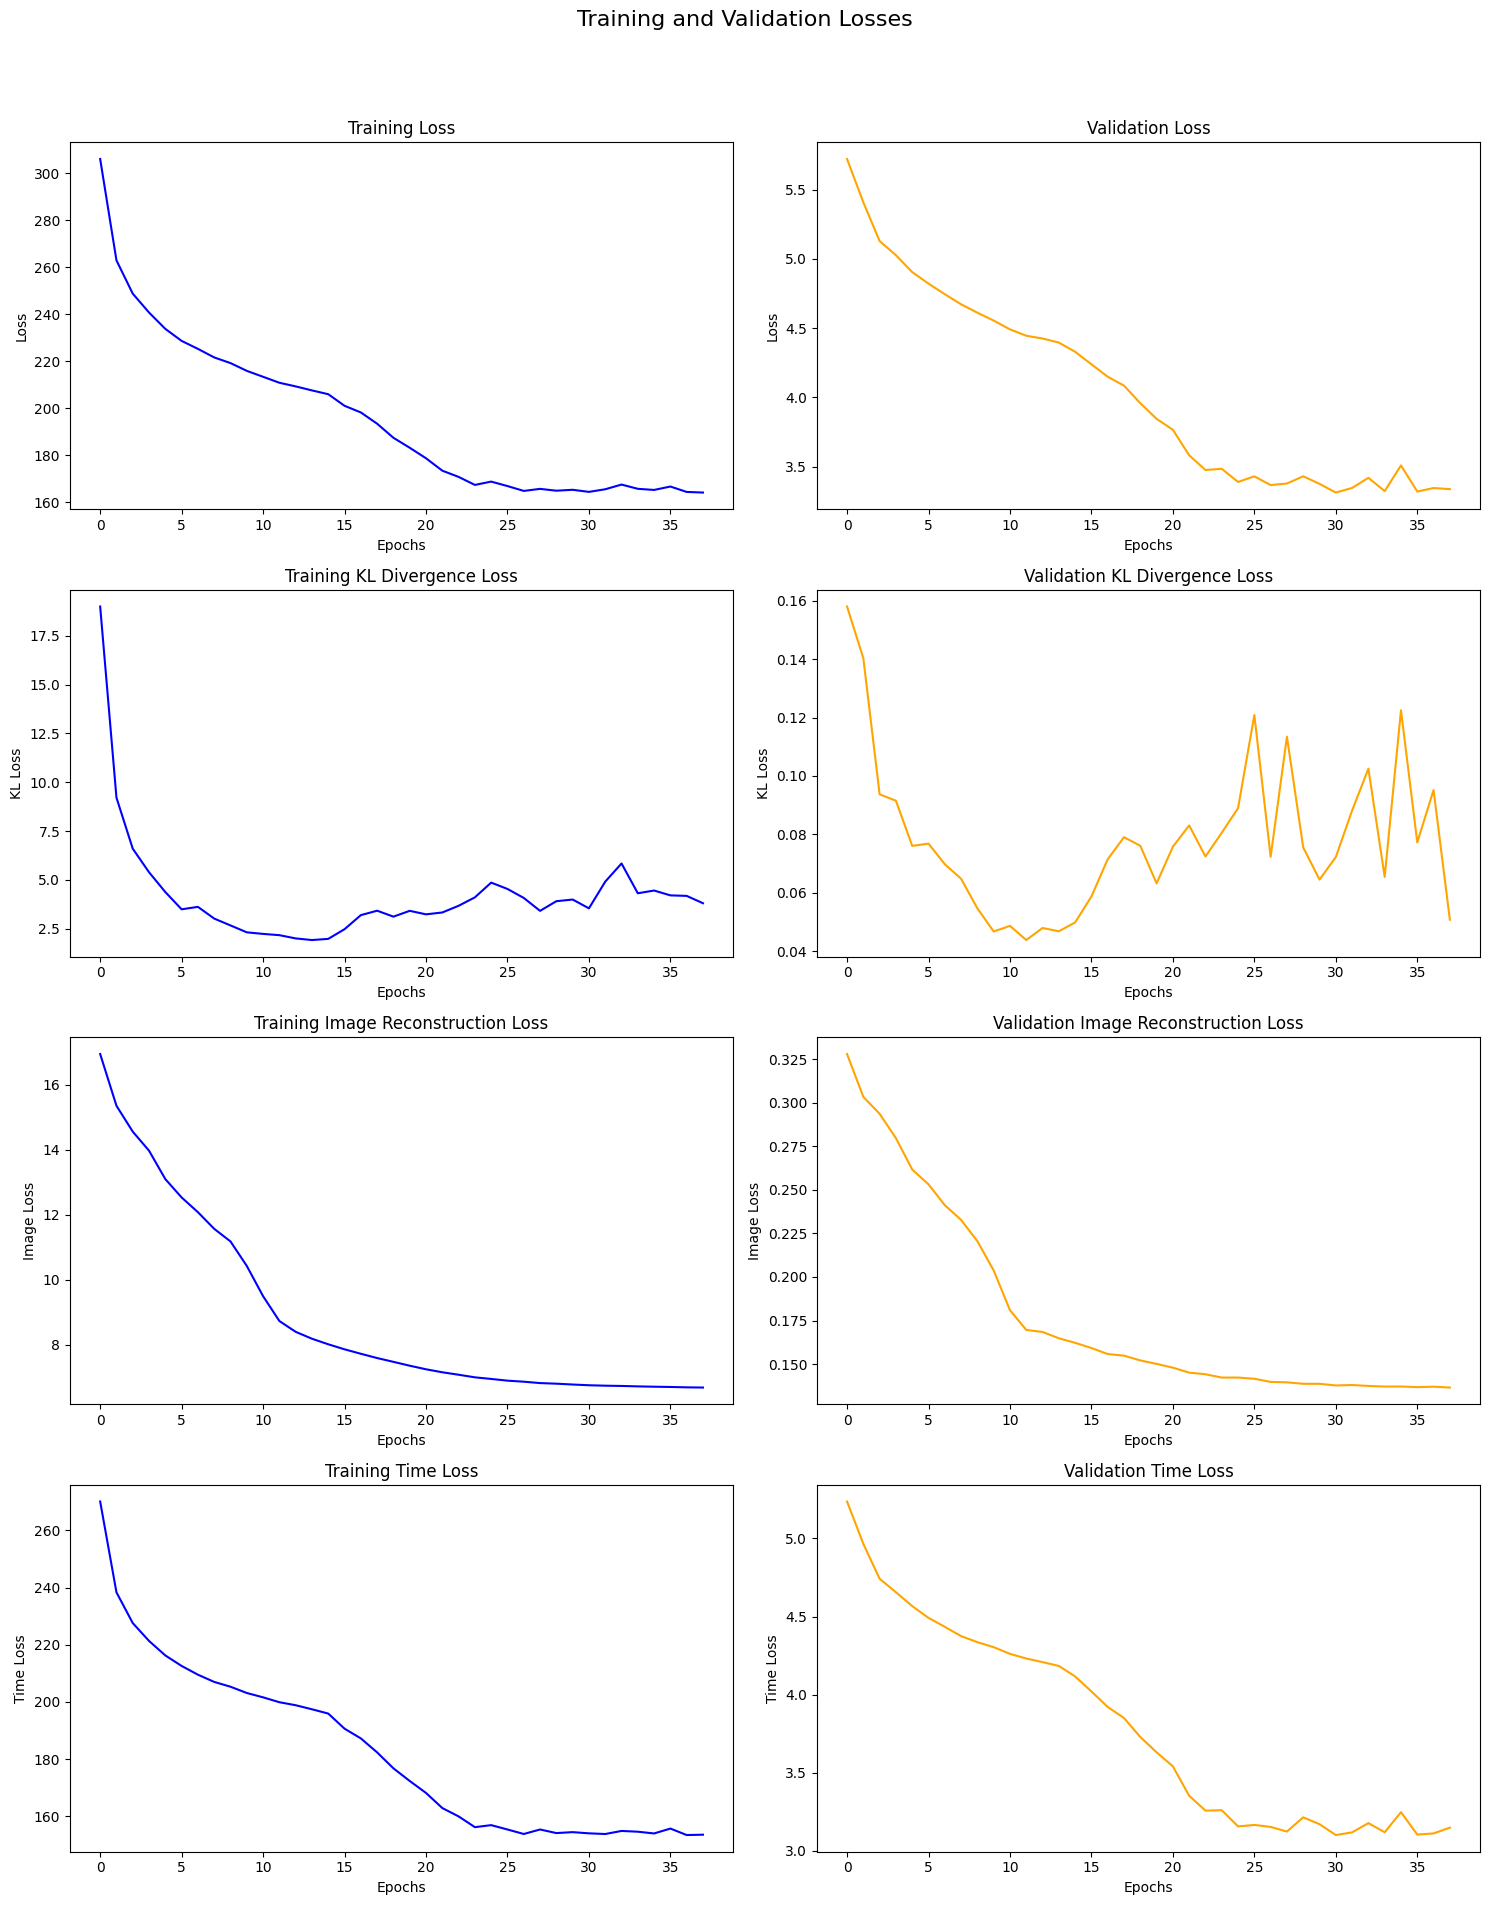

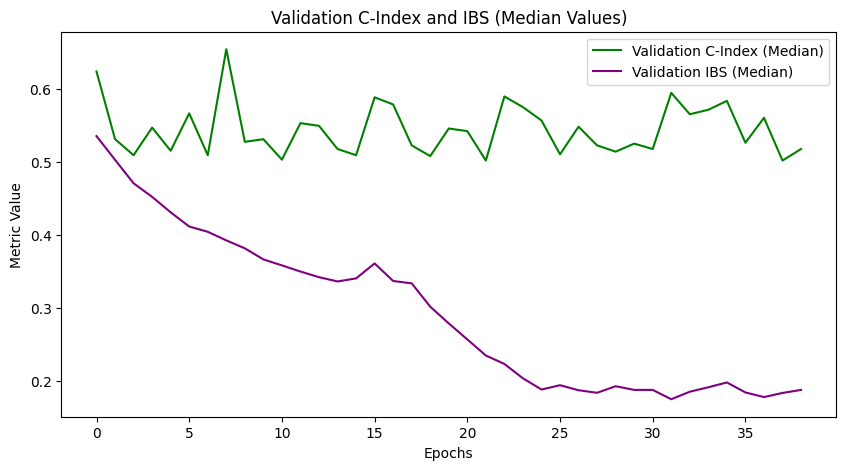

: 

In [ ]:
# Prepare the sliced training stats dictionary by removing the first two entries
sliced_training_stats = {key: values[2:] for key, values in training_stats.items()}

# Now call the plot functions with the sliced dictionary
plot_individual_losses(sliced_training_stats, filename="loss_plot_3.png")
plot_ci_ibs(sliced_training_stats, filename="metrics_plot_3.png")


In [ ]:
import torch
torch.cuda.empty_cache()


In [ ]:
epo

NameError: name 'epo' is not defined

In [ ]:
training_stats

{'loss_tr': [5711.4965131096415,
  603.5615448871254,
  306.0453880290118,
  262.89494044691617,
  248.7399767831733,
  240.69390485387726,
  233.7348937105382,
  228.61740882589407,
  225.23392719356713,
  221.58920931595037,
  219.17263992267743,
  215.87572974545844,
  213.34428808354903,
  210.80882038251175,
  209.26133240642238,
  207.54780132484382,
  205.93198418506407,
  200.99845438481475,
  198.17298365531033,
  193.37476881789644,
  187.3810068221061,
  183.13929682482694,
  178.6662196191481,
  173.38720747257773,
  170.73502420594434,
  167.32381212525266,
  168.7357352197745,
  166.834888001824,
  164.77148964211284,
  165.6410253152932,
  164.86224455026098,
  165.25022202139917,
  164.3601047021735,
  165.47326889713435,
  167.4729404945782,
  165.66543983587007,
  165.18765135663094,
  166.6362972177039,
  164.33422825498158,
  164.07747664364302],
 'loss_va': [27.189132812690787,
  7.376894178307862,
  5.722168355998528,
  5.408772476238695,
  5.1291740555381935,
  5

In [ ]:
{'loss_tr': [39427154214208.27,
  1.4547767196210246e+16,
  5149898781.378558,
  3516489246.138284,
  26052.89185099253,
  22286.172736871034,
  24698.1208088823,
  22445.553128275722,
  22114.715156656577,
  21214.14670786271,
  38839.98500754936,
  26846.555498231613,
  28893.177782986197,
  30542.647036807695,
  34596.04883187507,
  38383.570127051884,
  51672.584654298786,
  35315.986238163474,
  30288.281884514126,
  33915.837811963,
  37587.434245848686,
  35348.75098851864,
  31917.21126675101,
  28873.71859106064,
  85874.81732009917,
  33979.65206618376,
  31192.211900676048,
  31600.440576402274,
  30424.92745657078,
  503271506.8667287,
  35374.72162233475,
  16197847.098654952,
  55460.24697806923,
  52599.44020589403,
  50626.83530830356,
  50357.805165510385,
  52437.44966446844,
  54174.52239633975,
  56469.373069690184,
  62405.080480565644,
  129796.61154235908,
  65529.881775043075,
  68676.10931840271,
  68200.81294326368,
  72655.16610013072,
  87203.90209351784,
  90962.27048429329,
  96952.94306211857,
  86032.15957717571,
  548901.9123926922,
  978913.6598478789,
  95075.79057964253,
  100582.07671653017,
  6.064118452121902e+26,
  1.744178159747492e+25,
  7.125309044428506e+29,
  6872786873708077.0,
  7.713810741639359e+18,
  3331260001850.488,
  2.5511229566217956e+16],
 'loss_va': [15768858763.853058,
  4114.692680410397,
  8694881499.210815,
  26170.46145057101,
  457.5001294985364,
  453.3115262830986,
  652.1710644786925,
  436.11832339490456,
  422.4395824979592,
  3467.301076774621,
  638.3535496684937,
  1010.8013870465104,
  618.987505435078,
  834.4271101670556,
  878.2044392791605,
  888.5427017328375,
  710.4753730182563,
  1231.3579117438715,
  1216.325749392971,
  713.4372794540504,
  791.7856292866646,
  680.7659695548575,
  618.4956224750503,
  590.2413706158037,
  702.8334658392464,
  667.3211403070281,
  625.7509112883757,
  641.0360550485458,
  1184.1947820875062,
  748.0562747626536,
  726.2682636941375,
  1305.8718568330353,
  1114.0732652219463,
  1071.3612170068284,
  1011.0668207291963,
  1014.6709665855939,
  1180.53822339303,
  1102.1727930771833,
  1267.736344120458,
  1213.7680117918048,
  1463.1242967740584,
  62673453.026876524,
  1452.5135222815316,
  1332.387866622338,
  1846.579867526454,
  1897.3288826426447,
  1823.87925470799,
  1865.2689823798141,
  2750.585002510821,
  1816.146498719697,
  2053.6477812485255,
  1948.2190876713032,
  2137.206672688289,
  1988598979356.9958,
  4069241474371.703,
  1189686458694.726,
  2665702755737.954,
  27275251097629.88,
  1142745577.5043638,
  19677398666.014103],
 'kl_tr': [39427154213897.27,
  1.4547767196209994e+16,
  5149898558.642334,
  3516489041.6943054,
  25879.263610839844,
  22105.674041748047,
  24537.165924072266,
  22280.10366821289,
  21948.305236816406,
  21051.427856445312,
  38676.950134277344,
  26684.979431152344,
  28728.314331054688,
  30379.057250976562,
  34433.002197265625,
  38223.46417236328,
  51510.482360839844,
  35154.82501220703,
  30127.20263671875,
  33750.8662109375,
  37424.99450683594,
  35188.094665527344,
  31752.771850585938,
  28709.936950683594,
  85704.16040039062,
  33816.72479248047,
  31029.625610351562,
  31436.960815429688,
  30254.5517578125,
  503271330.2608032,
  35215.62469482422,
  16197691.04309082,
  55300.57598876953,
  52441.645446777344,
  50469.2890625,
  50203.019775390625,
  52278.1708984375,
  54017.403259277344,
  56310.98223876953,
  62248.201416015625,
  129641.29553222656,
  65370.58459472656,
  68518.66284179688,
  68043.62744140625,
  72496.47717285156,
  87048.80603027344,
  90804.78369140625,
  96796.63732910156,
  85875.650390625,
  548745.5815429688,
  978757.3547363281,
  94920.00354003906,
  100425.71313476562,
  6.064118452121902e+26,
  1.744178159747492e+25,
  7.125309044428506e+29,
  6872786873707867.0,
  7.713810741639359e+18,
  3331260001692.2812,
  2.5511229566217788e+16],
 'kl_va': [15768858757.595158,
  4106.87699620864,
  8694881494.6372,
  26165.57762594784,
  454.19212610581343,
  449.99278528550093,
  648.6424470789292,
  432.69517247817095,
  419.1309168198529,
  3463.6759769215305,
  634.8877204446231,
  1007.3388492359835,
  615.6823874080883,
  830.9399629480698,
  874.7926240808823,
  885.1887135225184,
  707.17237405216,
  1227.6647913315717,
  1212.9031838809742,
  710.0710772346048,
  788.4246036305148,
  677.4690300436581,
  615.1487678079044,
  586.8496811810662,
  699.5648660098805,
  664.0616311465992,
  622.3650045955883,
  637.7707950367648,
  1180.590030445772,
  744.8262365004596,
  723.1087179744945,
  1302.370361328125,
  1110.6995059742646,
  1068.1035982019762,
  1007.8762817382812,
  1011.5719855813419,
  1177.2124885110295,
  1098.9444831399358,
  1264.3411434397979,
  1210.5310776654412,
  1459.3807229434742,
  62673436.601526596,
  1449.2850485409008,
  1329.1327837775734,
  1843.3199391084559,
  1894.1582533892463,
  1820.535982019761,
  1862.124906652114,
  2747.3388671875,
  1812.9378662109375,
  2050.3522302964157,
  1944.931453929228,
  2134.038947610294,
  1988598979353.2537,
  4069241474367.8296,
  1189686458690.3835,
  2665702755734.0376,
  27275251097625.76,
  1142745573.2415268,
  19677398662.476406],
 'll_img_tr': [17.517240330576897,
  11.47467988729477,
  8.399418011307716,
  7.361917719244957,
  6.928893551230431,
  6.7395908534526825,
  6.636031940579414,
  6.56253307312727,
  6.506612114608288,
  6.472189046442509,
  6.434959329664707,
  6.399164378643036,
  6.370089456439018,
  6.355520471930504,
  6.331287056207657,
  6.281173177063465,
  6.237406603991985,
  6.218974739313126,
  6.207176350057125,
  6.2001480758190155,
  6.187242724001408,
  6.180736444890499,
  6.173148594796658,
  6.164739936590195,
  6.154403507709503,
  6.146331533789635,
  6.137076884508133,
  6.120281681418419,
  6.092786401510239,
  5.26882990449667,
  2.1004518028348684,
  0.47875839238986373,
  0.3865040522068739,
  0.3324318900704384,
  0.2981817699037492,
  0.27813846431672573,
  0.26390337478369474,
  0.2559678154066205,
  0.2393448487855494,
  0.232766707893461,
  0.2323947437107563,
  0.22403726540505886,
  0.21537205623462796,
  0.21029247343540192,
  0.20433223876170814,
  0.19916861364617944,
  0.20168407820165157,
  0.19178290641866624,
  0.1868824374396354,
  0.18133278214372694,
  0.18049478228203952,
  0.12553192116320133,
  0.11021492735017091,
  0.11287695507053286,
  0.10629109549336135,
  0.104121288866736,
  0.10098892019595951,
  0.09359701920766383,
  0.0909701167838648,
  0.09074881090782583],
 'll_img_va': [0.23210804602679083,
  0.2308625464930254,
  0.22193220170105205,
  0.19304727543802822,
  0.15178941365550547,
  0.14896267827819376,
  0.13710944661322763,
  0.1330443857347264,
  0.13306107109083848,
  0.13600346621345072,
  0.13098898135563908,
  0.13240477092125835,
  0.1302997399778927,
  0.1299137985881637,
  0.12922659034238143,
  0.1273675236631842,
  0.12717701932963202,
  0.12703242021448471,
  0.12632995624752605,
  0.12601281921653187,
  0.12585663839298136,
  0.12572343384518342,
  0.12566100280074513,
  0.12542303914532943,
  0.12521564828998902,
  0.12535309703911052,
  0.1258964148514411,
  0.12432780818027608,
  0.123887119047782,
  0.08885200979078517,
  0.016319322454578736,
  0.009671827011248645,
  0.007459876346675789,
  0.006220918395282591,
  0.005524248240844291,
  0.005099603084518629,
  0.004883724073057666,
  0.004665468929006773,
  0.0049355699516394555,
  0.004421586088617058,
  0.004919219542952145,
  12.360643577296287,
  0.003989884533974177,
  0.004084730644107741,
  0.003917969146962552,
  0.0036526705987532347,
  0.0036967749406090554,
  0.0033797066220465828,
  0.0042259662192972265,
  0.005310932064757627,
  0.004182809744687641,
  0.002240641720538192,
  0.0020709908088011775,
  0.002911669681506122,
  0.002887756152845481,
  0.0027157303274554364,
  0.0028367190731360633,
  0.0033602087950224385,
  0.0027554595486863572,
  0.004023529822006822],
 'll_time_tr': [294.309517422682,
  239.60610778348132,
  214.57490539714036,
  197.27588823548953,
  166.69928507456643,
  173.7591321347051,
  154.31877641159744,
  158.8868074749434,
  159.90329752571125,
  156.24671396622222,
  156.60039451224603,
  155.17701922771437,
  158.49333474400626,
  157.2341950108231,
  156.71521371101377,
  153.82482675892265,
  155.86541601754158,
  154.9421707806464,
  154.8722775805363,
  158.77152778331387,
  156.25242211821185,
  154.47553685847143,
  158.26632046194513,
  157.61678442000937,
  164.50305007964678,
  156.7809724337559,
  156.44914432839172,
  157.35946067961663,
  164.28292532078,
  171.47817899924473,
  156.99640260817932,
  155.5879737981982,
  159.28488090129986,
  157.46199544480942,
  157.24790595979906,
  154.50737498305398,
  159.01485001530946,
  156.86248423037983,
  158.1515120730185,
  156.64639853439508,
  155.0823675543803,
  159.0731812930693,
  157.231022504269,
  156.97517470898444,
  158.48482571666972,
  154.89696656470116,
  157.28488859016574,
  156.11408262636297,
  156.32205276163998,
  156.1388331218062,
  156.13067307394974,
  155.66130718159582,
  156.25323020205943,
  189.81416225402006,
  198.82493841210788,
  161.2699100739035,
  208.68359208064763,
  192.64577127425449,
  158.12634879723353,
  172.31940847337788],
 'll_time_va': [6.045626106697199,
  7.584813337786939,
  4.365946017523781,
  4.691147405787945,
  3.1562107542808784,
  3.169779313314593,
  3.3915091018543286,
  3.29010504701855,
  3.1756018568747155,
  3.4891476328473363,
  3.3348423931030715,
  3.3301328099525946,
  3.174822329609218,
  3.3572356840592765,
  3.2825930015869136,
  3.2266186101353247,
  3.1758232422912838,
  3.5660954812339067,
  3.2962083773461,
  3.2401861636093123,
  3.235171163962463,
  3.1712070893243034,
  3.2211976416403196,
  3.2662585983404977,
  3.1433808208641505,
  3.134157310704654,
  3.260005526657016,
  3.1409313984997373,
  3.4808610454565385,
  3.1411854359073437,
  3.1432277911045476,
  3.491841179312926,
  3.3663201392256497,
  3.2514003995216068,
  3.18500633351602,
  3.0938755929469353,
  3.320852069500564,
  3.2236281817332593,
  3.390274784520327,
  3.232510872687567,
  3.7386479344443777,
  5.112117506067385,
  3.2244741427445978,
  3.2509898989923545,
  3.2559862649654097,
  3.16697432462976,
  3.339581856427155,
  3.140693661983051,
  3.241891584810123,
  3.203326040469431,
  3.291386200272033,
  3.2854005734176384,
  3.16566424389627,
  3.7394885179727795,
  3.8714214574512793,
  4.340483235043096,
  3.9140906458492433,
  4.115132895396274,
  4.260237461045146,
  3.5339531114768468],
 'ci_va': [(0.397, 0.5216881594372802, 0.6443),
  (0.452, 0.577960140679953, 0.6967),
  (0.4084, 0.5334114888628371, 0.6554),
  (0.4266, 0.552168815943728, 0.6729),
  (0.3948, 0.5193434935521688, 0.6421),
  (0.4175, 0.5427901524032825, 0.6642),
  (0.4387, 0.5644783118405627, 0.6843),
  (0.4118, 0.536928487690504, 0.6587),
  (0.4555, 0.5814771395076201, 0.7),
  (0.4152, 0.5404454865181711, 0.662),
  (0.445, 0.570926143024619, 0.6903),
  (0.4301, 0.555685814771395, 0.6762),
  (0.4232, 0.548651817116061, 0.6696),
  (0.4175, 0.5427901524032825, 0.6642),
  (0.4084, 0.5334114888628371, 0.6554),
  (0.4106, 0.5357561547479485, 0.6576),
  (0.4462, 0.5720984759671747, 0.6914),
  (0.4038, 0.5287221570926143, 0.651),
  (0.4301, 0.555685814771395, 0.6762),
  (0.4543, 0.5803048065650644, 0.6989),
  (0.5227, 0.6483001172332943, 0.7601),
  (0.3768, 0.5005861664712778, 0.6243),
  (0.4118, 0.536928487690504, 0.6587),
  (0.3768, 0.5005861664712778, 0.6243),
  (0.4589, 0.5849941383352872, 0.7032),
  (0.4718, 0.5978898007033998, 0.715),
  (0.4427, 0.5685814771395076, 0.6881),
  (0.4882, 0.6143024618991794, 0.7298),
  (0.3875, 0.5117233294255569, 0.6349),
  (0.3925, 0.5169988276670574, 0.6399),
  (0.4072, 0.5322391559202814, 0.6543),
  (0.4531, 0.5791324736225087, 0.6978),
  (0.388, 0.5123094958968347, 0.6355),
  (0.4084, 0.5334114888628371, 0.6554),
  (0.405, 0.52989449003517, 0.6521),
  (0.3959, 0.5205158264947245, 0.6432),
  (0.4301, 0.5556858147713951, 0.6762),
  (0.5191, 0.6447831184056272, 0.757),
  (0.445, 0.570926143024619, 0.6903),
  (0.4347, 0.5603751465416178, 0.6805),
  (0.3813, 0.5052754982415005, 0.6288),
  (0.4782, 0.604337631887456, 0.7208),
  (0.3982, 0.5228604923798359, 0.6454),
  (0.379, 0.5029308323563892, 0.6265),
  (0.4129, 0.5381008206330598, 0.6598),
  (0.4555, 0.5814771395076201, 0.7),
  (0.3869, 0.511137162954279, 0.6343),
  (0.3846, 0.5087924970691676, 0.6321),
  (0.4278, 0.5533411488862837, 0.674),
  (0.4753, 0.6014067995310668, 0.7181),
  (0.4232, 0.548651817116061, 0.6696),
  (0.437, 0.5627198124267292, 0.6827),
  (0.4266, 0.552168815943728, 0.6729),
  (0.5396, 0.6647127784290738, 0.7746),
  (0.4683, 0.5943728018757327, 0.7118),
  (0.3937, 0.5181711606096131, 0.641),
  (0.4485, 0.5744431418522861, 0.6935),
  (0.3959, 0.5205158264947245, 0.6432),
  (0.4243, 0.5498241500586166, 0.6707),
  (0.379, 0.5029308323563892, 0.6265),
  (0.4555, 0.5814771395076201, 0.7)],
 'ibs_va': [(0.1887, 0.29273719681696, 0.4161),
  (0.1922, 0.2969072588854835, 0.4205),
  (0.2944, 0.41232991045352285, 0.5384),
  (0.2103, 0.31793152967841243, 0.4425),
  (0.1302, 0.22201786375113092, 0.34),
  (0.1336, 0.22633699952157718, 0.3447),
  (0.1333, 0.2259010954552005, 0.3443),
  (0.1251, 0.21564415691638067, 0.333),
  (0.1303, 0.22223736945000896, 0.3402),
  (0.134, 0.22681546045737147, 0.3453),
  (0.1313, 0.22343423340131097, 0.3416),
  (0.127, 0.2180084743249207, 0.3356),
  (0.128, 0.21926422169406445, 0.337),
  (0.1195, 0.20863475428185888, 0.3252),
  (0.1341, 0.22694070393019164, 0.3454),
  (0.1363, 0.22960663739240902, 0.3483),
  (0.1194, 0.20854963000059257, 0.3251),
  (0.166, 0.2657546477228875, 0.3874),
  (0.1504, 0.24691638034693972, 0.3672),
  (0.1209, 0.21036842888708965, 0.3271),
  (0.1088, 0.19491793475124694, 0.3099),
  (0.1403, 0.2345479472068905, 0.3537),
  (0.1246, 0.21498208897655838, 0.3322),
  (0.1339, 0.226605612950009, 0.345),
  (0.1373, 0.23085144090986073, 0.3497),
  (0.1079, 0.1937786502662107, 0.3086),
  (0.1161, 0.20434409290219366, 0.3204),
  (0.1365, 0.22983911198448037, 0.3486),
  (0.1303, 0.22212122621492256, 0.3401),
  (0.1361, 0.2294407471329756, 0.3481),
  (0.1254, 0.21605322685243902, 0.3334),
  (0.1444, 0.23957033969117636, 0.3592),
  (0.1299, 0.2216970115991078, 0.3396),
  (0.1347, 0.22762799575197662, 0.3462),
  (0.1282, 0.21956635671754265, 0.3373),
  (0.1202, 0.20946389194155274, 0.3261),
  (0.1277, 0.2188877046111507, 0.3365),
  (0.1408, 0.23516088549801176, 0.3544),
  (0.1374, 0.23096538796014848, 0.3498),
  (0.1251, 0.21571758717261322, 0.3331),
  (0.1632, 0.26238508660261955, 0.3838),
  (0.1558, 0.2534730912029142, 0.3742),
  (0.1218, 0.21148202476231362, 0.3284),
  (0.1298, 0.22159116242150131, 0.3395),
  (0.1192, 0.20824719246331888, 0.3248),
  (0.145, 0.24037519528862925, 0.3601),
  (0.1259, 0.2166894473308139, 0.3341),
  (0.1174, 0.20594122972188644, 0.3222),
  (0.1227, 0.2126683002314132, 0.3297),
  (0.116, 0.20419144741841666, 0.3203),
  (0.1541, 0.25138919349126637, 0.372),
  (0.1199, 0.20909292616721192, 0.3257),
  (0.1135, 0.20096407527602542, 0.3167),
  (0.1255, 0.21615832504629265, 0.3335),
  (0.1576, 0.2556284142663388, 0.3766),
  (0.1346, 0.22755312196923536, 0.3461),
  (0.1496, 0.2459224080098703, 0.3661),
  (0.127, 0.21805521677451536, 0.3356),
  (0.1237, 0.21396897821070773, 0.3311),
  (0.1209, 0.2103480617783792, 0.3271),
#   (0.1303, 0.22223736945000896, 0.3402)]}

In [ ]:
Cell In[97], line 24
     23 def kl_loss(self, latent_params):
---> 24     mu, log_var = latent_params
     25     kl = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())  # Kullback-Leibler divergence
     26     return kl / mu.shape[0]
     
ValueError: not enough values to unpack (expected 2, got 1)

SyntaxError: invalid syntax (3921441514.py, line 1)

In [ ]:
--> 242 loss_time = self.time_loss(out['time_params'], time_train_batch, censor_train_batch)
    243 loss = loss_kl + loss_img + loss_time
    244 loss.backward()

File ~/g17p3/g17-p3/g15p3/lib/python3.11/site-packages/torch/nn/modules/module.py:1518, in Module._wrapped_call_impl(self, *args, **kwargs)
   1516     return self._compiled_call_impl(*args, **kwargs)  # type: ignore[misc]
...
     44 if not torch.isfinite(loss):
---> 45     raise ValueError("Non-finite loss encountered, check inputs for stability issues.")
     47 return loss

ValueError: Non-finite loss encountered, check inputs for stability issues.

In [ ]:
import torch

# Set parameters
in_channels = 1            # Number of input channels
out_channels = 1           # Number of output channels
base_channels = 16         # Base channels for the model
latent_dim = 8             # Latent dimension for the VAE

# Create an instance of the UNet3D model
model = UNet3D(in_channels, out_channels, base_channels, latent_dim)

# Create a random tensor with the shape [4, 1, 128, 128, 64]
input_tensor = torch.rand(4, 1, 128, 128, 64)

# Pass the random input through the model
output_data = model(input_tensor)



In [ ]:
# Print the output shapes
for key, value in output_data.items():
    
    print(f"{key} shape: {value.shape}")

In [ ]:
time_info = model.predict_time(input_tensor)

In [ ]:
print("Latent Vector (z):", time_info['z'])
print("Weibull Parameters (time_params):", time_info['time_params'])
print("Sampled Time (time_samples):", time_info['time_samples'])


In [ ]:
just_time_info = model.predict_just_time(input_tensor)
print("Sampled Time (time_samples):", time_info['time_samples'])

In [ ]:
import numpy as np
import torch

# Set a random seed for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Define batch size
batch_size = 3

# Generate dummy time_train data (e.g., survival times)
# Let's assume time points are between 0 and 100
time_train = np.random.uniform(0, 100, size=batch_size)

# Generate dummy x_val data
# Shape: (3, 1, 128, 128, 64)
x_val = torch.rand(batch_size, 1, 128, 128, 64)

# Generate dummy censor_val data
# Let's assume a 50% censoring rate
#censor_val = np.random.randint(0, 2, size=batch_size)
censor_val = np.array([1, 1, 0]) 
# Print the shapes of the generated data
print("time_train shape:", time_train.shape)  # Expect (3,)
print("x_val shape:", x_val.shape)            # Expect (3, 1, 128, 128, 64)
print("censor_val shape:", censor_val.shape)  # Expect (3,)


In [ ]:
time_train

In [ ]:
censor_val

In [ ]:
risk = model.calculate_risk(time_train, x_val, censor_val)

In [ ]:
risk

In [ ]:
import scipy
print(scipy.__version__)


In [ ]:
from scipy.integrate import trapz

# Compute the integral using the trapezoidal rule
integral = trapz(y, x)
print(f"The integral using trapezoidal rule is approximately: {integral}")


In [ ]:
import scipy.integrate
print(dir(scipy.integrate))  # This will list all available functions and attributes


In [ ]:
from scipy.integrate import simps
import numpy as np
from scipy.integrate import simps

# Example data
x = np.linspace(0, 10, 100)
y = np.sin(x)

# Compute the integral using Simpson's rule
integral = simps(y, x)
print(f"The integral is approximately: {integral}")


In [ ]:
import torch
import torch.nn as nn
import numpy as np


class UNet3D(nn.Module):
    def __init__(self, in_channels, out_channels, base_channels, latent_dim=None):
        super(UNet3D, self).__init__()
        
        self.latent_dim = latent_dim
        
        # Encoder and decoder layers
        self.enc1 = Encoder3D(in_channels, base_channels)
        self.enc2 = Encoder3D(base_channels, base_channels * 2)
        self.enc3 = Encoder3D(base_channels * 2, base_channels * 4)
        self.enc4 = Encoder3D(base_channels * 4, base_channels * 8)
        
        if latent_dim is not None:
            self.latent_space = LatentSpaceGaussian(latent_dim)
            self.latent_mu = nn.Linear(base_channels * 8 * 8 * 8 * 4, self.latent_space.latent_params)
            self.fc_decode = nn.Linear(latent_dim, base_channels * 8 * 8 * 8 * 4)
        
        self.dec4 = Decoder3D(base_channels * 8, base_channels * 4)
        self.dec3 = Decoder3D(base_channels * 4, base_channels * 2)
        self.dec2 = Decoder3D(base_channels * 2, base_channels)
        self.dec1 = Decoder3D(base_channels, out_channels)

        if latent_dim is not None:
            self.time_decoder = TimeDecoder(latent_dim)
    
    def forward(self, x):
        enc1 = self.enc1(x)
        enc2 = self.enc2(enc1)
        enc3 = self.enc3(enc2)
        enc4 = self.enc4(enc3)
        
        if self.latent_dim is not None:
            enc4_flat = enc4.view(enc4.size(0), -1)
            latent_params = self.latent_mu(enc4_flat)
            mu, log_var = self.latent_space.get_latent_params(latent_params)
            z = self.latent_space.sample_latent((mu, log_var))
            enc4 = self.fc_decode(z)
            enc4 = enc4.view(enc4.size(0), -1, 8, 8, 4)
            kl_divergence = self.latent_space.kl_loss((mu, log_var))
            weibull_params = self.time_decoder(z)
        
        dec4 = self.dec4(enc4)
        dec3 = self.dec3(dec4 + enc3)
        dec2 = self.dec2(dec3 + enc2)
        dec1 = self.dec1(dec2 + enc1)

        if self.latent_dim is not None:
            return dec1, weibull_params, kl_divergence
        else:
            return dec1

    def predict_time(self, x, just_cov=False, device=torch.device('cpu')):
        """Predicts Weibull time distribution parameters and samples for survival analysis."""
        if not just_cov:
            cov = x.drop(['time', 'event'], axis=1)
        else:
            cov = x.copy()

        # Forward pass to get latent representations and time predictions
        out_params = self.forward(cov.to(device))
        z = out_params[1]  # Assuming 'z' is returned as the second output
        time_params = self.time_decoder(z)

        # Generate samples from time distribution
        time_samples = sample_from_dist(time_params, [self.time_dist])

        return {
            'z': z.detach().cpu().numpy(),
            'time_params': time_params.cpu().numpy(),
            'time_samples': time_samples
        }

    def predict_just_time(self, x):
        """Predicts only the time samples based on the input covariates."""
        return self.predict_time(x, just_cov=True)['time_samples']


    def calculate_risk(self, time_train, x_val, censor_val):
        """Calculate risk CDF at specified time points, compute C-index and IBS with confidence intervals."""
        times = np.unique(time_train)
        out_data = self.predict_time(x_val)
        pred_risk = np.zeros([out_data['time_params'].shape[0], len(times)])

        for sample in range(pred_risk.shape[0]):
            if self.time_dist[0] == 'weibull':
                alpha = out_data['time_params'][sample, 0]
                lam = out_data['time_params'][sample, 1]
                pred_risk[sample, :] = 1 - np.exp(-np.power(times / lam, alpha))
            else:
                raise RuntimeError('Unknown time distribution for risk calculation.')

        # Calculate C-index and IBS along with confidence intervals
        ci, ibs = obtain_c_index(pd.DataFrame(1 - pred_risk.T, index=times), np.array(x_val['time']), censor_val)
        ci_conf_intervals = bern_conf_interval(len(np.array(x_val['time'])), ci)
        ibs_conf_intervals = bern_conf_interval(len(np.array(x_val['time'])), ibs, ibs=True)

        return ci_conf_intervals, ibs_conf_intervals
     

    def fit_epoch(self, data, optimizer, batch_size=64, device=torch.device('cpu')):
        epoch_results = {'loss_tr': 0.0, 'loss_va': 0.0, 'kl_tr': 0.0, 'kl_va': 0.0, 'll_cov_tr': 0.0, 'll_cov_va': 0.0,
                         'll_time_tr': 0.0, 'll_time_va': 0.0, 'ci_va': 0.0, 'ibs_va': 0.0}

        for batch in range(n_batches):
    


    def fit(self, data, train_params):
        training_stats = {'loss_tr': [], 'loss_va': [], 'kl_tr': [], 'kl_va': [], 'll_cov_tr': [], 'll_cov_va': [],
                          'll_time_tr': [], 'll_time_va': [], 'ci_va': [], 'ibs_va': []}

        optimizer = torch.optim.Adam(self.parameters(), lr=train_params['lr'])

        for epoch in range(train_params['n_epochs']):       


In [ ]:
import torch

# Generate a random tensor
random_input = torch.tensor([100.0])
  # Scaling by 10 to get a wider range of values
softplus_output = torch.nn.functional.softplus(random_input)

random_input.item(), softplus_output.item()